# Statistical Simulation in Python


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

### Pytorch model framework example

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Define the Model Architecture
class SimpleClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(SimpleClassifier, self).__init__()
        # Define the layers
        self.fc1 = nn.Linear(input_size, hidden_size)  # Fully connected layer 1
        self.relu = nn.ReLU()                         # Activation function
        self.fc2 = nn.Linear(hidden_size, num_classes) # Fully connected layer 2
        
    def forward(self, x):
        # Define how data passes through the layers
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# 2. Hyperparameters & Configuration
INPUT_SIZE = 10
HIDDEN_SIZE = 32
NUM_CLASSES = 2
LEARNING_RATE = 0.01
EPOCHS = 5

# Check for GPU acceleration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate the model and move it to the configured device
model = SimpleClassifier(INPUT_SIZE, HIDDEN_SIZE, NUM_CLASSES).to(device)

# 3. Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# 4. Generate Dummy Data (for demonstration purposes)
# 100 samples of 10 features each
dummy_inputs = torch.randn(100, INPUT_SIZE).to(device)
# 100 random targets (0 or 1)
dummy_labels = torch.randint(0, NUM_CLASSES, (100,)).to(device)

# 5. The Training Loop
print(f"Starting training on device: {device}")
model.train()  # Set the model to training mode

for epoch in range(EPOCHS):
    # Clear the gradients from the previous step
    optimizer.zero_grad()
    
    # Forward pass: compute predictions
    outputs = model(dummy_inputs)
    
    # Compute the loss
    loss = criterion(outputs, dummy_labels)
    
    # Backward pass: compute gradients via autograd
    loss.backward()
    
    # Update parameters (weights and biases)
    optimizer.step()
    
    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {loss.item():.4f}")

# 6. Evaluation Mode Switch
model.eval()  # Set to evaluation mode for inference/testing


Starting training on device: cpu
Epoch [1/5], Loss: 0.7352
Epoch [2/5], Loss: 0.7023
Epoch [3/5], Loss: 0.6809
Epoch [4/5], Loss: 0.6671
Epoch [5/5], Loss: 0.6574


SimpleClassifier(
  (fc1): Linear(in_features=10, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=2, bias=True)
)

In [3]:
# 1. Set the model to evaluation mode
model.eval()

# 2. Prepare your inference data (ensure it matches the expected input shape)
# Let's create 5 new sample data points
new_samples = torch.randn(5, INPUT_SIZE).to(device)

# 3. Disable gradient calculations for faster performance and lower memory usage
with torch.no_grad():
    # Pass data through the model to get raw output logits
    logits = model(new_samples)
    
    # Apply Softmax to convert raw logits to probabilities (optional)
    probabilities = torch.softmax(logits, dim=1)
    
    # Get the predicted class indices (the highest logit score)
    predictions = torch.argmax(logits, dim=1)

# 4. View results
print("Raw Logits:\n", logits)
print("Class Probabilities:\n", probabilities)
print("Predicted Classes for the 5 samples:\n", predictions)

Raw Logits:
 tensor([[-0.5037,  0.0190],
        [ 0.0162,  0.1908],
        [-0.1082,  0.9821],
        [ 0.1003,  0.6574],
        [ 0.3010,  0.1720]])
Class Probabilities:
 tensor([[0.3722, 0.6278],
        [0.4565, 0.5435],
        [0.2516, 0.7484],
        [0.3642, 0.6358],
        [0.5322, 0.4678]])
Predicted Classes for the 5 samples:
 tensor([1, 1, 1, 1, 0])


### Compute-AUC-ROC-from-scratch-python

In [4]:
def get_metric(y, pred, threshold):
    tp = 0
    fp = 0
    tn = 0
    fn = 0
    for i in range(len(y)):
        if pred[i] > threshold:
            if y[i] == 1:
                tp += 1
            else:
                fp += 1
        elif pred[i] <= threshold:
            if y[i] == 0:
                tn += 1
            else:
                fn += 1

    tpr = tp/(tp + fn)
    fpr = fp/(fp + tn)

    return [tpr, fpr]

df = pd.DataFrame()
df['y'] = np.random.binomial(1, 0.6, 10)
df['pred'] = np.random.uniform(0.3, 1, 10)
df
            
get_metric(df['y'], df['pred'], 0.5)    


[1.0, 0.6666666666666666]

In [5]:
roc_points = []
thr = np.arange(0, 1, 0.05)
print(thr)

for t in thr:
    roc_points.append(get_metric(df['y'], df['pred'], t))

roc_points

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95]


[[1.0, 1.0],
 [1.0, 1.0],
 [1.0, 1.0],
 [1.0, 1.0],
 [1.0, 1.0],
 [1.0, 1.0],
 [1.0, 1.0],
 [1.0, 1.0],
 [1.0, 0.8333333333333334],
 [1.0, 0.8333333333333334],
 [1.0, 0.6666666666666666],
 [1.0, 0.5],
 [1.0, 0.5],
 [0.5, 0.5],
 [0.25, 0.3333333333333333],
 [0.25, 0.16666666666666666],
 [0.25, 0.16666666666666666],
 [0.25, 0.16666666666666666],
 [0.0, 0.16666666666666666],
 [0.0, 0.0]]

In [6]:
fpr_array = []
tpr_array = []
for i in range(len(roc_points)-1):
    p1 = roc_points[i]
    p2 = roc_points[i+1]
    tpr_array.append([p1[0], p2[0]])
    fpr_array.append([p1[1], p2[1]])

#We use Trapezoidal rule to calculate the area under the curve and approximating the intergral  
auc = sum(np.trapz(tpr_array,fpr_array))+1
print('Area under curve={}'.format(auc))

Area under curve=0.39583333333333337


/tmp/ipykernel_16/767952735.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc = sum(np.trapz(tpr_array,fpr_array))+1


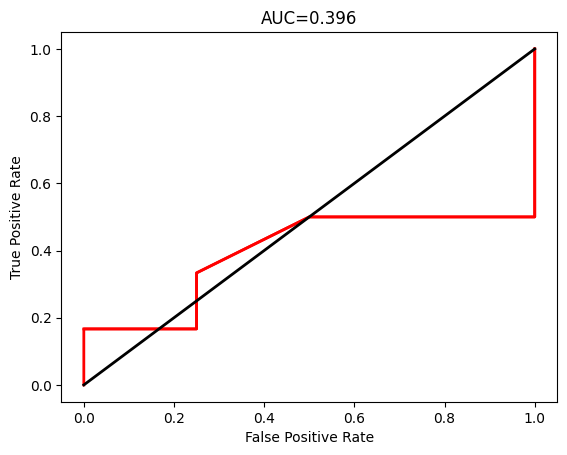

In [7]:
plt.plot(tpr_array,fpr_array, 'r', lw=2)
plt.plot([0, 1], [0, 1], 'k-', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC={}'.format(round(auc,3)))
plt.show()

### np.random.choice()
In this exercise, you will be introduced to the np.random.choice() function. This is a remarkably useful function for simulations and you will be making extensive use of it later in the course. As a first step, let's try to understand the basics of this function. Using help(), figure out which of the following input parameters are not optional for the np.random.choice() function:

### Poisson random variable
The numpy.random module also has a number of useful probability distributions for both discrete and continuous random variables. In this exercise, you will learn how to draw samples from a probability distribution.
In particular, you will draw samples from a very important discrete probability distribution, the Poisson distribution, which is typically used for modeling the average rate at which events occur.
Following the exercise, you should be able to apply these steps to any of the probability distributions found in numpy.random. In addition, you will also see how the sample mean changes as we draw more samples from a distribution.


In [8]:
# Initialize seed and parameters
np.random.seed(123) 
lam, size_1, size_2 = 5, 3, 1000  

# Draw samples & calculate absolute difference between lambda and sample mean
samples_1 = np.random.poisson(lam, size_1)
samples_2 = np.random.poisson(lam, size_2)
answer_1 = abs(np.mean(samples_1) - lam)
answer_2 = abs(np.mean(samples_2) - lam) 

print("|Lambda - sample mean| with {} samples is {} and with {} samples is {}. ".format(size_1, answer_1, size_2, answer_2))


|Lambda - sample mean| with 3 samples is 0.33333333333333304 and with 1000 samples is 0.07699999999999996. 


### Shuffling a deck of cards
Often times we are interested in randomizing the order of a set of items. Consider a game of cards where you first shuffle the deck of cards or a game of scrabble where the letters are first mixed in a bag. As the final exercise of this section, you will learn another useful function - np.random.shuffle(). This function allows you to randomly shuffle a sequence in place. At the end of this exercise, you will know how to shuffle a deck of cards or any sequence of items.
Examine deck_of_cards in the shell.


In [9]:
# Shuffle the deck
deck_of_cards = np.random.choice(np.arange(52), 10, replace = False)
np.random.shuffle(deck_of_cards)
print(deck_of_cards)


# Print out the top three cards
card_choices_after_shuffle = deck_of_cards[0:3]
print(card_choices_after_shuffle)


[27  5 10  0 37  6 40 12 11  1]
[27  5 10]


### Throwing a fair die

Once you grasp the basics of designing a simulation, you can apply it to any system or process. Next, we will learn how each step is implemented using some basic examples.
As we have learned, simulation involves repeated random sampling. The first step then is to get one random sample. Once we have that, all we do is repeat the process multiple times. This exercise will focus on understanding how we get one random sample. We will study this in the context of throwing a fair six-sided die.
By the end of this exercise, you will be familiar with how to implement the first two steps of running a simulation - defining a random variable and assigning probabilities.
For the rest of the course, look to the IPython shell to find out what seed has been set.


In [10]:
# Define die outcomes and probabilities
die, probabilities, throws = [1,2,3,4,5,6], [1/6,1/6,1/6,1/6,1/6,1/6], 10

# Use np.random.choice to throw the die once and record the outcome
outcome = np.random.choice(die, size=throws, p=probabilities)
print("Outcome of the throw: {}".format(outcome))


Outcome of the throw: [1 2 5 2 1 4 1 6 5 5]


### Throwing two fair dice
We now know how to implement the first two steps of a simulation. Now let's implement the next step - defining the relationship between random variables.
Often times, our simulation will involve not just one, but multiple random variables. Consider a game where throw you two dice and win if each die shows the same number. Here we have two random variables - the two dice - and a relationship between each of them - we win if they show the same number, lose if they don't. In reality, the relationship between random variables can be much more complex, especially when simulating things like weather patterns.
By the end of this exercise, you will be familiar with how to implement the third step of running a simulation - defining relationships between random variables.




In [11]:
# Initialize number of dice, simulate & record outcome
die, probabilities, num_dice = [1,2,3,4,5,6], [1/6, 1/6, 1/6, 1/6, 1/6, 1/6], 20
outcomes = np.random.choice(die, size=num_dice, p=probabilities) 
answer = []
# Win if the two dice show the same number
if outcomes[0] == outcomes[1]: 
    answer = 'win' 
else:
    answer = 'lose'

print("The dice show {} and {}. You {}!".format(outcomes[0], outcomes[1], answer))


The dice show 5 and 5. You win!


#### Simulating the dice game
We now know how to implement the first three steps of a simulation. Now let's consider the next step - repeated random sampling.
Simulating an outcome once doesn't tell us much about how often we can expect to see that outcome. In the case of the dice game from the previous exercise, it's great that we won once. But suppose we want to see how many times we can expect to win if we played this game multiple times, we need to repeat the random sampling process many times. Repeating the process of random sampling is helpful to understand and visualize inherent uncertainty and deciding next steps.
Following this exercise, you will be familiar with implementing the fourth step of running a simulation - sampling repeatedly and generating outcomes.


In [12]:
# Initialize model parameters & simulate dice throw
die, probabilities, num_dice = [1,2,3,4,5,6], [1/6, 1/6, 1/6, 1/6, 1/6, 1/6], 2
sims, wins = 100, 0

for i in range(sims):
    outcomes = np.random.choice(die,size = num_dice,p=probabilities) 
    # Increment `wins` by 1 if the dice show same number
    if outcomes[1] == outcomes[0]: 
        wins = wins + 1 

print("In {} games, you win {} times".format(sims, wins))

In 100 games, you win 21 times


### Simulating one lottery drawing
In the last three exercises of this chapter, we will be bringing together everything you've learned so far. We will run a complete simulation, take a decision based on our observed outcomes, and learn to modify inputs to the simulation model.
We will use simulations to figure out whether or not we want to buy a lottery ticket. Suppose you have the opportunity to buy a lottery ticket which gives you a shot at a grand prize of $1 Million. Since there are 1000 tickets in total, your probability of winning is 1 in 1000. Each ticket costs 10 dollar. Let's use our understanding of basic simulations to first simulate one drawing of the lottery.


In [13]:
# Pre-defined constant variables
lottery_ticket_cost, num_tickets, grand_prize = 10, 1000, 1000000

# Probability of winning
chance_of_winning = 1/num_tickets

# Simulate a single drawing of the lottery
gains = [-lottery_ticket_cost, grand_prize-lottery_ticket_cost]
probability = [1-chance_of_winning, chance_of_winning]
outcome = np.random.choice(a=gains, size=1, p=probability, replace=True)

print("Outcome of one drawing of the lottery is {}".format(outcome))


Outcome of one drawing of the lottery is [-10]


### Should we buy?
In the last exercise, we simulated the random drawing of the lottery ticket once. In this exercise, we complete the simulation process by repeating the process multiple times.
Repeating the process gives us multiple outcomes. We can think of this as multiple universes where the same lottery drawing occurred. We can then determine the average winnings across all these universes. If the average winnings are greater than what we pay for the ticket then it makes sense to buy it, otherwise, we might not want to buy the ticket.
This is typically how simulations are used for evaluating business investments. After completing this exercise, you will have the basic tools required to use simulations for decision-making.


In [14]:
# Initialize size and simulate outcome
lottery_ticket_cost, num_tickets, grand_prize = 10, 1000, 1000000
chance_of_winning = 1/num_tickets
size = 2000
payoffs = [-lottery_ticket_cost, grand_prize - lottery_ticket_cost]
probs = [1 - chance_of_winning, chance_of_winning]

outcomes = np.random.choice(a=payoffs, size=size, p=probs, replace=True)

# Mean of outcomes.
answer = np.mean(outcomes)
print("Average payoff from {} simulations = {}".format(size, answer))

Average payoff from 2000 simulations = 490.0


### Calculating a break-even lottery price
Simulations allow us to ask more nuanced questions that might not necessarily have an easy analytical solution. Rather than solving a complex mathematical formula, we directly get multiple sample outcomes. We can run experiments by modifying inputs and studying how those changes impact the system. For example, once we have a moderately reasonable model of global weather patterns, we could evaluate the impact of increased greenhouse gas emissions.
In the lottery example, we might want to know how expensive the ticket needs to be for it to not make sense to buy it. To understand this, we need to modify the ticket cost to see when the expected payoff is negative.

In [15]:
# Initialize simulations and cost of ticket
sims, lottery_ticket_cost = 3000, 0

# Use a while loop to increment `lottery_ticket_cost` till average value of outcomes falls below zero
while 1:
    outcomes = np.random.choice([-lottery_ticket_cost, grand_prize-lottery_ticket_cost],
                 size=sims, p=[1-chance_of_winning, chance_of_winning], replace=True)
    if outcomes.mean() < 0:
        break
    else:
        lottery_ticket_cost += 1
answer = lottery_ticket_cost - 1

print("The highest price at which it makes sense to buy the ticket is {}".format(answer))


The highest price at which it makes sense to buy the ticket is 12


### Queen and spade
In this example, you'll use the generalized probability formula
P(A∪B)=P(A)+P(B)−P(A∩B)

to calculate the probability of two events. Consider a deck of cards (13 cards x 4 suites = 52 cards in total). One card is drawn at random. What is the probability of getting a queen or a spade? Here event A is the card being a queen and event B is the card being a spade. Think carefully about whether the two events have anything in common.

### Two of a kind
Now let's use simulation to estimate probabilities. Suppose you've been invited to a game of poker at your friend's home. In this variation of the game, you are dealt five cards and the player with the better hand wins. You will use a simulation to estimate the probabilities of getting certain hands. Let's work on estimating the probability of getting at least two of a kind. Two of a kind is when you get two cards of different suites but having the same numeric value (e.g., 2 of hearts, 2 of spades, and 3 other cards).
By the end of this exercise, you will know how to use simulation to calculate probabilities for card games.


In [16]:
suits = ['Hearts', 'Diamonds', 'Clubs', 'Spades']
ranks = ['A', '2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K']

# Generate a list of (rank, suit) tuples
deck_of_cards = [[rank, suit] for suit in suits for rank in ranks]
deck_of_cards[:5]

[['A', 'Hearts'],
 ['2', 'Hearts'],
 ['3', 'Hearts'],
 ['4', 'Hearts'],
 ['5', 'Hearts']]

In [17]:
# Shuffle deck & count card occurrences in the hand
n_sims, two_kind = 4, 0
for i in range(n_sims):
    np.random.shuffle(deck_of_cards)
    hand, cards_in_hand = deck_of_cards[0:5], {}
    print('hand:', hand)
    for card in hand:
        # Use .get() method on cards_in_hand
        cards_in_hand[card[1]] = cards_in_hand.get(card[1], 0) + 1
    print(cards_in_hand)
    
    # Condition for getting at least 2 of a kind
    highest_card = max(cards_in_hand.values())
    if  highest_card>=2: 
        two_kind += 1
        
print(two_kind)
print("Probability of seeing at least two of a kind = {} ".format(two_kind/n_sims))


hand: [['8', 'Diamonds'], ['9', 'Clubs'], ['5', 'Spades'], ['4', 'Spades'], ['K', 'Clubs']]
{'Diamonds': 1, 'Clubs': 2, 'Spades': 2}
hand: [['5', 'Spades'], ['2', 'Diamonds'], ['5', 'Clubs'], ['J', 'Clubs'], ['Q', 'Hearts']]
{'Spades': 1, 'Diamonds': 1, 'Clubs': 2, 'Hearts': 1}
hand: [['2', 'Hearts'], ['5', 'Hearts'], ['3', 'Diamonds'], ['K', 'Hearts'], ['J', 'Spades']]
{'Hearts': 3, 'Diamonds': 1, 'Spades': 1}
hand: [['J', 'Clubs'], ['J', 'Hearts'], ['8', 'Clubs'], ['7', 'Clubs'], ['A', 'Diamonds']]
{'Clubs': 3, 'Hearts': 1, 'Diamonds': 1}
4
Probability of seeing at least two of a kind = 1.0 


### Game of thirteen
A famous French mathematician Pierre Raymond De Montmart, who was known for his work in combinatorics, proposed a simple game called as Game of Thirteen. You have a deck of 13 cards, each numbered from 1 through 13. Shuffle this deck and draw cards one by one. A coincidence is when the number on the card matches the order in which the card is drawn. For instance, if the 5th card you draw happens to be a 5, it's a coincidence. You win the game if you get through all the cards without any coincidences. Let's calculate the probability of winning at this game using simulation.
By completing this exercise, you will further strengthen your ability to cast abstract problems into the simulation framework for estimating probabilities.

In [18]:
# Pre-set constant variables
deck, sims, coincidences = np.arange(1, 14), 10000, 0

for i in range(sims):
    # Draw all the cards without replacement to simulate one game
    draw = np.random.choice(deck, size=len(deck), replace=False)
    # Check if there are any coincidences
    coincidence = (draw == list(np.arange(1, 14))).any()
    if coincidence == True: 
        coincidences += 1

# Calculate probability of winning
prob_of_winning = 1 - coincidences/sims
print("Probability of winning = {}".format(prob_of_winning))

Probability of winning = 0.373


In [19]:
cards = np.arange(1,14)
print(cards)

win = 0
nsim = 5000
for i in range(nsim):
    np.random.shuffle(cards)
    coin = 0
    for j in range(1,len(cards)+1):
        draw = np.random.choice(cards, size = 1, replace = False)
        if draw == j:
            coin += 1
    if coin == 0:
        win += 1

print('probability:', win/nsim)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13]
probability: 0.3544


### The conditional urn
As we've learned, conditional probability is defined as the probability of an event given another event. To illustrate this concept, let's turn to an urn problem.
We have an urn that contains 7 white and 6 black balls. Four balls are drawn at random. We'd like to know the probability that the first and third balls are white, while the second and the fourth balls are black.
Upon completion, you will learn to manipulate simulations to calculate simple conditional probabilities.


In [20]:
# Initialize success, sims and urn
success, sims = 0, 5000
urn = ['w','w','w','w','w','w','w','b','b','b','b','b','b']

for _ in range(sims):
    # Draw 4 balls without replacement
    draw = np.random.choice(urn, replace=False, size=4)
    # Count the number of successes
    if draw[0]=='w' and draw[2]=='w' and draw[1]=='b' and draw[3]=='b': 
        success +=1

print("Probability of success = {}".format(success/sims))

Probability of success = 0.0684


In [21]:
# urn = ['w','w','w','w','w','w','w','b','b','b','b','b','b']

# cond_cnt = 0
# prob_cnt = 0
# nsim = 1000

# for i in range(nsim):
#     draw = np.random.choice(urn, size = 4, replace = False)

#     if draw[1] == 'b' and draw[3] == 'b':
#         cond_cnt += 1
#         if draw[0] == 'w' and draw[2] == 'w':
#             prob_cnt += 1

# ans = prob_cnt/cond_cnt
# print(ans)

### Birthday problem
Now we'll use simulation to solve a famous probability puzzle - the birthday problem. It sounds quite straightforward - How many people do you need in a room to ensure at least a 50% chance that two of them share the same birthday?
With 366 people in a 365-day year, we are 100% sure that at least two have the same birthday, but we only need to be 50% sure. Simulation gives us an elegant way of solving this problem.
Upon completion of this exercise, you will begin to understand how to cast problems in a simulation framework.

In [22]:
np.random.choice(366,2)

array([  9, 310])

In [23]:
np.random.choice(np.arange(366),2)

array([234, 304])

In [24]:
# Draw a sample of birthdays & check if each birthday is unique
days = np.arange(1,366)
people = 2

def birthday_sim(people):
    sims, unique_birthdays = 2000, 0 
    for _ in range(sims):
        draw = np.random.choice(365, size=people, replace=True)
        if len(draw) == len(set(draw)): 
            unique_birthdays += 1
    out = 1 - unique_birthdays / sims
    return out

# Break out of the loop if probability greater than 0.5
while (people > 0):
    prop_bds = birthday_sim(people)
    if prop_bds > 0.5: 
        break
    people += 1

print("With {} people, there's a 50% chance that two share a birthday.".format(people))
     

With 23 people, there's a 50% chance that two share a birthday.


### Data Generation Process (DGP)
Driving test
Through the next exercises, we will learn how to build a data generating process (DGP) through progressively complex examples.
In this exercise, you will simulate a very simple DGP. Suppose that you are about to take a driving test tomorrow. Based on your own practice and based on data you have gathered, you know that the probability of you passing the test is 90% when it's sunny and only 30% when it's raining. Your local weather station forecasts that there's a 40% chance of rain tomorrow. Based on this information, you want to know what is the probability of you passing the driving test tomorrow.
This is a simple problem and can be solved analytically. Here, you will learn how to model a simple DGP and see how it can be used for simulation.

In [25]:
np.random.binomial(n = 5, p = 0.9)

3

In [26]:
d = {'sunny': 0.9, 'rain': 0.3}
nsim = 10000
pas = 0

for i in range(nsim):
    draw = np.random.choice(['sunny','rain'], p = [0.6, 0.4], size = 1)
    if draw == 'sunny':
        res = np.random.binomial(1,d['sunny'])
        if res == 1:
            pas += 1
            
    elif draw == 'rain':
        res = np.random.binomial(1,d['rain'])
        if res == 1:
            pas += 1

pas/nsim
    

0.6522

In [27]:
sims, outcomes, p_rain, p_pass = 1000, [], 0.40, {'sun':0.9, 'rain':0.3}

def test_outcome(p_rain):
    # Simulate whether it will rain or not
    weather = np.random.choice(['rain', 'sun'], p=[p_rain, 1-p_rain])
    # Simulate and return whether you will pass or fail
    return np.random.choice(['pass', 'fail'], p=[p_pass[weather], 1-p_pass[weather]])

test_outcome(p_rain)

np.str_('fail')

### National elections
This exercise will give you a taste of how you can model a DGP at different levels of complexity.
Consider national elections in a country with two political parties - Red and Blue. This country has 50 states and the party that wins the most states wins the elections. You have the probability p
of Red winning in each individual state and want to know the probability of Red winning nationally.
Let's model the DGP to understand the distribution. Suppose the election outcome in each state follows a binomial distribution with probability p such that 0
indicates a loss for Red and 1
indicates a win. We then simulate a number of election outcomes. Finally, we can ask rich questions like what is the probability of Red winning less than 45% of the states?

In [28]:
import numpy as np

# Set random seed for reproducibility
np.net_seed = np.random.seed(42)

# Define parameters
n_states = 50
p = 0.6  # Probability of Red winning an individual state (adjust as needed)
n_simulations = 3000

# Simulate outcomes for 50 states across 10,000 elections
# 1 = Red wins state, 0 = Red loses state
elections = np.random.binomial(n=1, p=p, size=(n_simulations, n_states))

# Calculate the fraction of states Red wins in each simulated election
red_win_fractions = np.mean(elections, axis=1)

# Calculate the probability of Red winning less than 45% of the states
# 45% of 50 states = 22.5 states (i.e., winning <= 22 states)
prob_red_wins = np.mean(red_win_fractions < 0.45)

print(f"Probability of Red winning less than 45% of states: {prob_red_wins:.4f}")

print(len(elections), len(elections[0]))
print(len(red_win_fractions))

Probability of Red winning less than 45% of states: 0.0143
3000 50
3000


In [29]:
outcomes, nsims, probs = [], 1000, 0.6
np.net_seed = np.random.seed(42)

for i in range(nsims):
    election = []
    for _ in range(50):
        # Simulate elections in the 50 states
        election.append(np.random.binomial(p=probs, n = 1))
        # Get average of Red wins and add to `outcomes`
    outcomes.append(np.mean(election))

print(len(outcomes))
print(len(election))
# Calculate probability of Red winning in less than 45% of the states
prob_red_wins = sum([x<0.45 for x in outcomes])/len(outcomes)
print("Probability of Red winning in less than 45% of the states = {}".format(prob_red_wins))

1000
50
Probability of Red winning in less than 45% of the states = 0.013


### Fitness goals
Let's model how activity levels impact weight loss using modern fitness trackers. On days when you go to the gym, you average around 15k steps, and around 5k steps otherwise. You go to the gym 40% of the time. Let's model the step counts in a day as a Poisson random variable with a mean
λ
λ
dependent on whether or not you go to the gym.
For simplicity, let’s say you have an 80% chance of losing 1lb and a 20% chance of gaining 1b when you get more than 10k steps. The probabilities are reversed when you get less than 8k steps. Otherwise, there's an even chance of gaining or losing 1lb. Given all this, find the probability of losing weight in a month.
Examine the prob variable in the shell, which is the default probability of gaining or losing 1lb.


In [30]:
# Simulate steps & choose prob 
sims = 1000
days = 30
for _ in range(sims):
    w = []
    for i in range(days):
        lam = np.random.choice([5000, 15000], p=[0.6, 0.4], size=1)
        steps = np.random.poisson(lam)
        if steps > 10000: 
            prob = [0.2,0.8]
        elif steps < 8000: 
            prob = [0.8,0.2]
        else:
            prob = [0.5, 0.5]
        w.append(np.random.choice([1, -1], p=prob))
    outcomes.append(sum(w))

# Calculate fraction of outcomes where there was a weight loss
weight_loss_outcomes_frac = sum([x<0 for x in outcomes])/len(outcomes)
print("Probability of Weight Loss = {}".format(weight_loss_outcomes_frac))

Probability of Weight Loss = 0.098


### Sign up Flow
We will now model the DGP of an eCommerce ad flow starting with sign-ups.
On any day, we get many ad impressions, which can be modeled as Poisson random variables (RV). You are told that λ
is normally distributed with a mean of 100k visitors and standard deviation 2000.
During the signup journey, the customer sees an ad, decides whether or not to click, and then whether or not to signup. Thus both clicks and signups are binary, modeled using binomial RVs. What about probability p
of success? Our current low-cost option gives us a click-through rate of 1% and a sign-up rate of 20%. A higher cost option could increase the clickthrough and signup rate by up to 20%, but we are unsure of the level of improvement, so we model it as a uniform RV.

In [31]:
nsim = 10

crt = {'low': 0.01, 'high': np.random.uniform(0.01, 0.01*1.2)}
sign = {'low': 0.2, 'high': np.random.uniform(0.2, 0.2*1.2)}


def get_signup(cost, crt, sign, nsim):
    lam = np.random.normal(100000, 2000, size = nsim) # n parameters
    
    imp = np.random.poisson(lam)
    click = np.random.binomial(imp, crt[cost])
    signup = np.random.binomial(click, sign[cost])
    return signup
                           
get_signup('high', crt, sign, nsim)
    

array([279, 271, 273, 285, 270, 251, 280, 294, 267, 279])

In [32]:
get_signup('high', crt, sign, 1)


array([239])

In [33]:
imp = np.random.poisson(lam)
lam

array([15000])

### Purchase Flow
After signups, let's model the revenue generation process. Once the customer has signed up, they decide whether or not to purchase - a natural candidate for a binomial RV. Let's assume that 10% of signups result in a purchase.
Although customers can make many purchases, let's assume one purchase. The purchase value could be modeled by any continuous RV, but one nice candidate is the exponential RV. Suppose we know that purchase value per customer has averaged around $1000. We use this information to create the purchase_values RV. The revenue, then, is simply the sum of all purchase values.
The variables ct_rate, su_rate and the function get_signups() from the last exercise are pre-loaded for you.


In [34]:
nsim = 100



n_sign = get_signup('high', crt, sign, 1)
print(n_sign)
n_pur = np.random.binomial(n_sign, p = 0.1,)
print(n_pur)
pv = np.random.exponential(scale = 1000, size = n_pur)
rev = np.sum(pv)
rev
    


[224]
[24]


np.float64(33401.83314367606)

In [35]:
def get_revenue(signups):
    rev = []
    #np.random.seed(123)
    for s in signups:
        # Model purchases as binomial, purchase_values as exponential
        purchases = np.random.binomial(s, p=0.1)
        purchase_values = np.random.exponential(scale=1000,size=purchases)
        
        # Append to revenue the sum of all purchase values.
        rev.append(purchase_values.sum())
    return rev

print("Simulated Revenue = ${}".format(get_revenue(get_signup('high', crt, sign, 1))[0]))

Simulated Revenue = $18851.60747292063


### Probability of losing money
In this exercise, we will use the DGP model to estimate probability.
As seen earlier, this company has the option of spending extra money, let's say 3000, to redesign the ad. This could potentially get them higher clickthrough and signup rates, but this is not guaranteed. We would like to know whether or not to spend this extra $3000 by calculating the probability of losing money. In other words, the probability that the revenue from the high-cost option minus the revenue from the low-cost option is lesser than the cost.
Once we have simulated revenue outcomes, we can ask a rich set of questions that might not have been accessible using traditional analytical methods.
This simple yet powerful framework forms the basis of Bayesian methods for getting probabilities.

In [36]:
get_diff = get_revenue(get_signup('high', crt, sign, 1))[0]- get_revenue(get_signup('low', crt, sign, 1))[0]
get_diff

np.float64(14136.601396494127)

In [37]:
nsim = 3000
get_diff = []
for _ in range(nsim):
    diff = get_revenue(get_signup('high', crt, sign, 1))[0]- get_revenue(get_signup('low', crt, sign, 1))[0]
    get_diff.append(diff)
        

res = sum([get_diff[i]<3000 for i in range(nsim)])/nsim
print("Probability of losing money = {}".format(res))

Probability of losing money = 0.35633333333333334


In [38]:
# Initialize cost_diff
sims, cost_diff = 100, 3000

# Get revenue when the cost is 'low' and when the cost is 'high'
rev_low = get_revenue(get_signup('low', crt, sign, sims))
rev_high = get_revenue(get_signup('high', crt, sign, sims))

# calculate fraction of times rev_high - rev_low is less than cost_diff
frac = sum([rev_high[i]-rev_low[i]<cost_diff for i in range(sims)])/sims
print("Probability of losing money = {}".format(frac))

Probability of losing money = 0.44


In [39]:
rev_low[:5]

[np.float64(21072.645977291646),
 np.float64(34664.86189848887),
 np.float64(24119.275014399518),
 np.float64(25391.998681361732),
 np.float64(18025.446012608052)]

### Bootstrap

Sampling with replacement
In this example, you will review the np.random.choice() function that you've already seen in the previous chapters. You are given multiple variations of np.random.choice() for sampling from arrays. Look at each variation carefully and use the console to test out the options. Select the option that could generate ['a', 'c', 'c'] as an output.

Probability example
In this exercise, we will review the difference between sampling with and without replacement. We will calculate the probability of an event using simulation, but vary our sampling method to see how it impacts probability.

Consider a bowl filled with colored candies - three blue, two green, and five yellow. Draw three candies at random, with replacement and without replacement. You want to know the probability of drawing a yellow candy on the third draw given that the first candy was blue and the second candy was green.

In [40]:
can =['b','b','b','g','g','y','y','y','y','y']

nsim = 10000
cnt = 0

for _ in range(nsim):
    draw = np.random.choice(can, size = 3, replace = True)
    if draw[0] == 'b' and draw[1] == 'g' and draw[2] == 'y':
        cnt += 1

res = cnt/nsim
res


0.0281

In [41]:
nsim = 10000
cnt = 0

for _ in range(nsim):
    draw = np.random.choice(can, size = 3, replace = False)
    if draw[0] == 'b' and draw[1] == 'g' and draw[2] == 'y':
        cnt += 1

res = cnt/nsim
res

0.0433

In [42]:
# Set up the bowl
success_rep, success_no_rep, sims = 0, 0, 10000
bowl = ['b','b','b','g','g','y','y','y','y','y']

for i in range(sims):
    # Sample with and without replacement & increment success counters
    sample_rep = np.random.choice(bowl, size=3, replace=True)
    sample_no_rep = np.random.choice(bowl, size=3, replace=False)
    if (sample_rep[0] == 'b') & (sample_rep[1] == 'g') & (sample_rep[2] == 'y'): 
        success_rep += 1
    if (sample_no_rep[0]=='b') & (sample_no_rep[1]== 'g') & (sample_no_rep[2] == 'y'): 
        success_no_rep += 1

# Calculate probabilities
prob_with_replacement = success_rep/sims
prob_without_replacement = success_no_rep/sims
print("Probability with replacement = {}, without replacement = {}".format(prob_with_replacement, prob_without_replacement))


Probability with replacement = 0.0294, without replacement = 0.0383


### Running a simple bootstrap
Welcome to the first exercise in the bootstrapping section. We will work through an example where we learn to run a simple bootstrap. As we saw in the video, the main idea behind bootstrapping is **sampling with replacement**.

Suppose you own a factory that produces wrenches. You want to be able to characterize the average length of the wrenches and ensure that they meet some specifications. Your factory produces thousands of wrenches every day, but it's infeasible to measure the length of each wrench. However, you have access to a representative sample of 100 wrenches. Let's use bootstrapping to get the 95% confidence interval (CI) for the average lengths.
Examine the list wrench_lengths, which has 100 observed lengths of wrenches, in the shell.


In [43]:
wrench_lengths = np.random.normal(40, 5, size = 100)

nsim = 200
means = []

for _ in range(nsim):
    boots = np.random.choice(wrench_lengths, 100, replace = True)
    means.append(np.mean(boots))

ci5, ci95 = np.percentile(means, [2.5,97.5])

print([ci5, ci95])

print(len(means))

[np.float64(39.042786224715826), np.float64(41.09208083350537)]
200


### Non-standard estimators
In the last exercise, you ran a simple bootstrap that we will now modify for more complicated estimators.

Suppose you are studying the health of students. You are given the height and weight of 1000 students and are interested in the median height as well as the correlation between height and weight and the associated 95% CI for these quantities. 

Let's use bootstrapping.
Examine the pandas DataFrame df with the heights and weights of 1000 students. Using this, calculate the 95% CI for both the median height as well as the correlation between height and weight.

In [44]:
df = pd.DataFrame()
df['weight'] = np.random.normal(loc = 130, scale = 30, size = 1000)
df['height'] = np.random.normal(loc = 175, scale = 20, size = 1000)
df.head()

,weight,height
0,102.270130,187.753381
1,102.981316,132.409019
2,95.952811,175.180644
3,82.270469,221.722885
4,127.041160,173.333580


In [45]:
nsim = 1000
mheight = []
corrhw = []

for _ in range(nsim):
    hsample = np.random.choice(df.height.values, size = len(df), replace = True)
    wsample = np.random.choice(df.weight.values, size = len(df), replace = True)
    mheight.append(np.median(hsample))
    corrhw.append(np.corrcoef(hsample, wsample)[0, 1])

ci_mheight = np.percentile(mheight, [2.5,97.5])
ci_corrhw = np.percentile(corrhw, [2.5,97.5])

print(ci_mheight)

print(ci_corrhw)
    

[174.52951686 177.4249576 ]
[-0.0649511   0.05982514]


In [46]:
# Sample with replacement and calculate quantities of interest
sims, data_size, height_medians, hw_corr = 1000, df.shape[0], [], []
for i in range(sims):
    tmp_df = df.sample(n=df.shape[0], replace=True)
    height_medians.append(tmp_df['height'].median())
    hw_corr.append(tmp_df['weight'].corr(tmp_df['height']))

# Calculate confidence intervals
height_median_ci = np.percentile(height_medians, [2.5, 97.5])
height_weight_corr_ci = np.percentile(hw_corr, [2.5, 97.5])
print("Height Median CI = {} \nHeight Weight Correlation CI = {}".format( height_median_ci, height_weight_corr_ci))



Height Median CI = [174.60566378 177.4249558 ] 
Height Weight Correlation CI = [-0.02992301  0.08289001]


### Bootstrapping regression
Now let's see how bootstrapping works with regression. Bootstrapping helps estimate the uncertainty of non-standard estimators. Consider the R2
statistic associated with a regression. When you run a simple least squares regression, you get a value for R2. But let's see how can we get a 95% CI forR2.


In [47]:
import statsmodels.api as sm

df = pd.DataFrame()
n = 200
df['y'] = np.random.exponential(80, n)
df['x1'] = np.random.normal(7,1, n)
df['x2'] = np.random.normal(5,1, n)
df['x3'] = np.random.normal(25,2, n)

df.head()

,y,x1,x2,x3
0,29.877886,7.598273,4.998096,27.299551
1,37.089987,6.191213,5.990406,26.326432
2,183.015327,7.532295,5.379755,26.304473
3,70.257980,4.327545,7.267646,26.820096
4,38.390159,5.431220,5.165197,23.840120


In [48]:
nsim = 100
r2s = []

for _ in range(nsim):
    df_sample = df.sample(len(df), replace = True)
    lr = sm.OLS(df_sample['y'], df_sample.iloc[:, 1:]).fit()
    r2s.append(lr.rsquared)

np.percentile(r2s, [2.5, 97.5])

array([0.45238328, 0.57158444])

In [49]:
rsquared_boot, coefs_boot, sims = [], [], 1000
reg_fit = sm.OLS(df['y'], df.iloc[:,1:]).fit()

# Run 1K iterations
for i in range(sims):
    # First create a bootstrap sample with replacement with n=df.shape[0]
    bootstrap = df.sample(n=df.shape[0],replace=True)
    # Fit the regression and append the r square to rsquared_boot
    rsquared_boot.append(sm.OLS(bootstrap['y'],bootstrap.iloc[:,1:]).fit().rsquared)

# Calculate 95% CI on rsquared_boot
r_sq_95_ci = np.percentile(rsquared_boot, [2.5, 97.5])
print("R Squared 95% CI = {}".format(r_sq_95_ci))

R Squared 95% CI = [0.45790254 0.5655907 ]


### Basic jackknife estimation - mean
Jackknife resampling is an older procedure, which isn't used as often compared as bootstrapping. However, it's still useful to know how to run a basic jackknife estimation procedure. In this first exercise, we will calculate the jackknife estimate for the mean.

Let's return to the wrench factory.
You own a wrench factory and want to measure the average length of the wrenches to ensure that they meet some specifications. Your factory produces thousands of wrenches every day, but it's infeasible to measure the length of each wrench. However, you have access to a representative sample of 100 wrenches. Let's use jackknife estimation to get the average lengths.
Examine the variable wrench_lengths in the shell.


In [50]:
wrench_lengths = np.random.normal(6, 2, 100)
wrench_lengths[:3]

array([8.50396403, 6.29412769, 5.2945733 ])

In [51]:
n = len(wrench_lengths)
mean_len = []
for i in range(n):
    jk_dt = list(wrench_lengths[:i]) + list(wrench_lengths[i+1:])
    mean_len.append(np.mean(jk_dt))

mean_len
# The jackknife estimate is the mean of the mean lengths from each sample
jk_est = np.mean(mean_len).tolist()
jk_est

5.903094340745189

### Jackknife confidence interval for the median
In this exercise, we will calculate the jackknife 95% CI for a non-standard estimator. Here, we will look at the median. Keep in mind that the variance of a jackknife estimator is n-1 times the variance of the individual jackknife sample estimates where n is the number of observations in the original sample

Returning to the wrench factory, you are now interested in estimating the median length of the wrenches along with a 95% CI to ensure that the wrenches are within tolerance.

Let's revisit the code from the previous exercise, but this time in the context of median lengths. By the end of this exercise, you will have a much better idea of how to use jackknife resampling to calculate confidence intervals for non-standard estimators.

In [52]:
med_len = []

for i in range(n):
    jk_dt = list(wrench_lengths[:i]) + list(wrench_lengths[i+1:])
    med_len.append(np.median(jk_dt))

median_est = np.mean(med_len).tolist()
CI_est = np.percentile(med_len, [2.5, 97.5])
print('median estimate = {}'.format(median_est))
print('CI estimate = {}'.format(CI_est))

median estimate = 6.040642842114568
CI estimate = [5.99334799 6.0879377 ]


In [53]:
jk_var = (n-1) * np.var(med_len)
jk_25 = median_est - 1.96 * np.sqrt(jk_var)
jk_975 = median_est + 1.96 * np.sqrt(jk_var)
print('CI lower CI estimate = {},CI lower CI estimate = {} '.format(jk_25, jk_975))

CI lower CI estimate = 5.11831025885132,CI lower CI estimate = 6.962975425377817 


### Generating a single permutation
In the next few exercises, we will run a  **significance test using permutation testing**. As discussed in the video, we want to see if there's any difference in the donations generated by the two designs - A and B. Suppose that you have been running both the versions for a few days and have generated 500 donations on A and 700 donations on B, stored in the variables donations_A and donations_B.

We first need to generate a null distribution for the difference in means. We will achieve this by generating multiple permutations of the dataset and calculating the difference in means for each case.

First, let's generate one permutation and calculate the difference in means for the permuted dataset.


In [54]:
donations_A = np.random.normal(20, 3, 500)
donations_B = np.random.normal(10, 2.5, 700)
lena, lenb = len(donations_A), len(donations_B)

data = np.concatenate([donations_A, donations_B])
print(len(data))

# Get a single permutation of the concatenated length
perm = np.random.permutation(lena+lenb)

perma = data[perm[:lena]]
permb = data[perm[-lenb:]]

diffm = np.mean(perma) - np.mean(permb)

print('difference in means for the permuted dataset is {}'.format(diffm))

1200
difference in means for the permuted dataset is -0.2520457646302674


### Hypothesis testing - Difference of means
We want to test the hypothesis that there is a difference in the average donations received from A and B. Previously, you learned how to generate one permutation of the data. Now, we will generate a null distribution of the difference in means and then calculate the p-value.

For the null distribution, we first generate multiple permuted datasets and store the difference in means for each case. We then calculate the test statistic as the difference in means with the original dataset. Finally, we calculate the p-value as twice the fraction of cases where the difference is greater than or equal to the absolute value of the test statistic (2-sided hypothesis). A p-value of less than say 0.05 could then determine statistical significance.

In [55]:
n = 100
diffm = []
donations_A = np.random.normal(10, 3, 500)
donations_B = np.random.normal(10, 2.5, 700)
lena, lenb = len(donations_A), len(donations_B)

data = np.concatenate([donations_A, donations_B])

for i in range(n):

    
    perm = np.random.permutation(lena+lenb)

    perma = data[perm[:lena]]
    permb = data[perm[-lenb:]]
    diffm.append( np.mean(perma) - np.mean(permb))

diffm[:3]

[np.float64(0.10110321597296767),
 np.float64(0.1429304114047465),
 np.float64(0.2555965653454795)]

In [56]:
diff = np.mean(donations_A) - np.mean(donations_B)
print(diff)

pvalue = round(np.sum(diffm>abs(diff))/n*2, 5)
pvalue

0.06233014302633855


np.float64(0.72)

- answer

In [57]:

# Generate permutations equal to the number of repetitions
reps = n
perm = np.array([np.random.permutation(len(donations_A) + len(donations_B)) for i in range(reps)])
permuted_A_datasets = data[perm[:, :len(donations_A)]]
permuted_B_datasets = data[perm[:, len(donations_A):]]

# Calculate the difference in means for each of the datasets
samples = np.mean(permuted_A_datasets, axis=1) - np.mean(permuted_B_datasets, axis=1)

# Calculate the test statistic and p-value
test_stat = np.mean(donations_A) - np.mean(donations_B)
p_val = 2*np.sum(samples >= np.abs(test_stat))/reps
print("p-value = {}".format(p_val))

p-value = 0.78


### Hypothesis testing - Non-standard statistics
In the previous two exercises, we ran a permutation test for the difference in mean values. Now let's look at non-standard statistics.

Suppose that you're interested in understanding the distribution of the donations received from websites A and B. For this, you want to see if there's a statistically significant difference in the median and the 80th percentile of the donations. Permutation testing gives you a wonderfully flexible framework for attacking such problems.

Let's go through running a test to see if there's a difference in the median and the 80th percentile of the distribution of donations. As before, you're given the donations from the websites A and B in the variables donations_A and donations_B respectively.

In [58]:
# Median
n = 100
diffmed = []
donations_A = np.random.normal(10, 3, 500)
donations_B = np.random.normal(10, 2.5, 700)
lena, lenb = len(donations_A), len(donations_B)

data = np.concatenate([donations_A, donations_B])

for i in range(n):

    
    perm = np.random.permutation(lena+lenb)

    perma = data[perm[:lena]]
    permb = data[perm[-lenb:]]
    diffmed.append( np.median(perma) - np.median(permb))

diff = np.median(donations_A) - np.median(donations_B)
print(diff)

pvalue = round(np.sum(diffmed>abs(diff))/n*2, 5)
pvalue


0.336801788771929


np.float64(0.16)

In [59]:
# Median
n = 100
diff80 = []
donations_A = np.random.normal(10, 3, 500)
donations_B = np.random.normal(10, 2.5, 700)
lena, lenb = len(donations_A), len(donations_B)

data = np.concatenate([donations_A, donations_B])

for i in range(n):

    
    perm = np.random.permutation(lena+lenb)

    perma = data[perm[:lena]]
    permb = data[perm[-lenb:]]
    diff80.append( np.percentile(perma, 80) - np.percentile(permb, 80))

diff = np.percentile(donations_A, 80) - np.percentile(donations_B, 80)
print(diff)

pvalue = round(np.sum(diff80>abs(diff))/n*2, 5)
pvalue

0.5170708415585779


np.float64(0.08)

In [60]:
# answer
# Calculate the difference in 80th percentile and median for each of the permuted datasets (A and B)
samples_percentile = np.percentile(permuted_A_datasets, 80,axis = 1 ) - np.percentile(permuted_B_datasets, 80, axis=1 ) 
samples_median = np.median(permuted_A_datasets,axis=1) - np.median(permuted_B_datasets, axis=1)
#print(samples_median, samples_percentile,)

## Simulate Business Plan

### Modeling Corn Production
Suppose that you manage a small corn farm and are interested in optimizing your costs. In this exercise, we will model the production of corn.

For simplicity, let's assume that corn production depends on only two factors: rain, which you don't control, and cost, which you control. Rain is normally distributed with mean 50 and standard deviation 15. For now, let's fix cost at 5,000. Corn produced in any season is a Poisson random variable while the average corn production is governed by the equation:

100×(cost)**0.1×(rain)**0.2

100×(cost)**0.1×(rain)**0.2

Let's model this production function and simulate one outcome.


In [61]:
rain = np.random.normal(50, 15, 1)
cost = 5000
prod = np.random.poisson(100*(cost)**0.1*(rain)**0.2, 1).tolist()

print("Simulated Corn Production = {}".format(prod))


Simulated Corn Production = [474]


- Answer

In [62]:
# Corn Production Model
def corn_produced(rain, cost):
  mean_corn = 100*(cost**0.1)*(rain**0.2)
  corn = np.random.poisson(mean_corn)
  return corn

### Modeling Profits
In the previous exercise, you built a model of corn production. For a small farm, you typically have no control over the price or demand for corn. Suppose that price is normally distributed with mean 40 and standard deviation 10. 

You are given a function corn_demanded(), which takes the price and determines the demand for corn. This is reasonable because demand is usually determined by the market and is not in your control.

In this exercise, you will work on a function to calculate the profit by pulling together all the other simulated variables. The only input to this function will be the cost. Upon completion, you will have a function that will give you one simulated profit outcome for a given cost. This function can then be used for planning your costs.

In [63]:
def corn_demanded(price):
    return 1000 - 18 * price


def get_profit(cost):
    price = np.random.normal(40, 10)
    rain = np.random.normal(50, 15)
    demand = corn_demanded(price)
    supply = corn_produced(rain, cost)
    if demand >= supply:
        
        profit = price * supply - cost
        return profit
    else:
        profit2 = price * demand - cost
        return profit2

get_profit(200)

7583.743178469996

### Optimizing Costs

Now we will use the functions you've built to optimize our cost of production. We are interested in maximizing average profits. However, our profits depend on a number of factors, but we only control cost. Thus, we can simulate the uncertainty in the other factors and vary cost to see how our profits are impacted.

Since you manage the small corn farm, you have the ability to choose your cost - from 100 to 5,000. You want to choose the cost that gives you the maximum average profit. In this exercise, we will simulate multiple outcomes for each cost level and calculate an average. We will then choose the cost that gives us the maximum mean profit. Upon completion, you will have a framework for selecting optimal inputs for business decisions.

In [64]:
nsim = 20


d = {}

for cost in np.arange(100, 5100, 100):
    profit = []
    for i in range(nsim):
        profit.append(get_profit(cost))
    d[cost] = (np.mean(profit)).tolist() 
    k, v = max(d.items(), key = lambda x: x[1])   
    

k, v

/tmp/ipykernel_16/3763389852.py:4: ComplexWarning: Casting complex values to real discards the imaginary part
  corn = np.random.poisson(mean_corn)


(np.int64(100), 9478.851430490731)

### Monte Carlo Integration

	0.	Get the limits of the x-axis (xmin,xmax) and y-axis (max(f(x)),min(min(f(x)),0))	
    0.	Generate a number of uniformly distributed point in this box.
	0.	Multiply the area of the box ((max(f(x)−min(f(x))×(xmax−xmin) by the fraction of points that lie below f(x).

Upon completion, you will have a framework for handling definite integrals using Monte Carlo Integration.


In [65]:
def mc_integral(func, xmin, xmax, nsim):
    x = np.random.uniform(xmin, xmax, nsim)
    y = np.random.uniform(min(min(func(x)),0), max(func(x)), nsim)

    area = (max(y) - min(y)) * (xmax - xmin)
    res = area * sum(abs(y) <= abs(func(x)))/nsim
    return res

# Call the sim_integrate function and print results
result = mc_integral(func = lambda x: x*np.exp(x), xmin = 0, xmax = 1, nsim = 150)
print("Simulated answer = {}, Actual Answer = 1".format(result))

Simulated answer = 1.021438081446513, Actual Answer = 1


### Calculating the value of pi
Now we work through a classic example - estimating the value of π.

To estimate π, we randomly sample multiple points in this square & get the fraction of points inside the circle. After this exercise, you'll have a grasp of how to use simulation for computation.


In [66]:
nsim = 1000
res = 0

for i in range(nsim):
    x = np.random.uniform(-1, 1, 2)
    within_circle = x[0]**2 + x[1]**2 <= 1
    if within_circle == True:
        res += 1

print('pie estimate is {}'.format(4*res/nsim))
    
    

pie estimate is 3.088


### Power Analysis - Part I
Now we turn to power analysis. You typically want to ensure that any experiment or A/B test you run has at least 80% power. One way to ensure this is to calculate the sample size required to achieve 80% power.

Suppose that you are in charge of a news media website and you are interested in increasing the amount of time users spend on your website. Currently, the time users spend on your website is normally distributed with a mean of 1 minute and a variance of 0.5 minutes. Suppose that you are introducing a feature that loads pages faster and want to know the sample size required to measure a 10% increase in time spent on the website.

In this exercise, we will set up the framework to run one simulation, run a t-test, & calculate the p-value.

In [67]:
# # Initialize effect_size, control_mean, control_sd
# effect_size, sample_size, control_mean, control_sd = 0.05, 50, 1, 0.5

# # Simulate control_time_spent and treatment_time_spent, assuming equal variance
# control_time_spent = np.random.normal(loc=control_mean, scale=control_sd, size=sample_size)
# treatment_time_spent = np.random.normal(loc=control_mean*(1+effect_size), scale=control_sd, size=sample_size)

# # Run the t-test and get the p_value
# t_stat, p_value = ttest_ind(control_time_spent, treatment_time_spent)
# stat_sig = p_value < 0.05
# print("P-value: {}, Statistically Significant? {}".format(p_value, stat_sig))


In [68]:
from scipy.stats import ttest_ind

nsim = 100
# Simulate control_time_spent and treatment_time_spent, assuming equal variance

control = np.random.normal(1, 0.5, nsim)
treatment = np.random.normal(1*1.1, 0.5, nsim)
# Run the t-test and get the p_value

t_stat, p_value = ttest_ind(control, treatment)

stat_sig = p_value < 0.05

print('p-value is {},'.format(p_value), 'Significance:{}'.format(stat_sig))
p_value

p-value is 0.133102371831212, Significance:False


np.float64(0.133102371831212)

### Power Analysis - Part II
Previously, we simulated one instance of the experiment & generated a p-value. We will now use this framework to calculate statistical power. 

Power of an experiment is the experiment's ability to detect a difference between treatment & control if the difference really exists. It's good statistical hygiene to strive for 80% power.

For our website, we want to know how many people need to visit each variant, such that we can detect a 10% increase in time spent with 80% power. 

For this, we start with a small sample (50), simulate multiple instances of this experiment & check power. If 80% power is reached, we stop. If not, we increase the sample size & try again.


In [69]:
sample_size = 50
sims = 100

# Keep incrementing sample size by 10 till we reach required power

while 1:
    control = np.random.normal(1, 0.5, (sample_size,sims))
    treatment = np.random.normal(1*1.05, 0.5, (sample_size,sims))
    
    t_stat, p_value = ttest_ind(control, treatment)
    # Power is the fraction of times in the simulation when the p-value was less than 0.05

    power = sum(p_value<0.05)/sims

    if power>= 0.8:
        break
    else:
        sample_size += 10

print("For 80% power, sample size required = {}".format(sample_size))


For 80% power, sample size required = 1300


In [70]:
len(p_value)

100

### Portfolio Simulation - Part I
In the next few exercises, you will calculate the expected returns of a stock portfolio & characterize its uncertainty.

Suppose you have invested $10,000 in your portfolio comprising of multiple stocks. You want to evaluate the portfolio's performance over 10 years. You can tweak your overall expected rate of return and volatility (standard deviation of the rate of return). Assume the rate of return follows a normal distribution.

First, let's write a function that takes the principal (initial investment), number of years, expected rate of return and volatility as inputs and returns the portfolio's total value after 10 years.

Upon completion of this exercise, you will have a function you can call to determine portfolio performance.


In [71]:
ppl = 10000
def get_portfolio(ppl, rate, vol, year):
    roi = np.random.normal(rate, vol, size = year)
    res = ppl
    for i in range(year):
        res  = res * (1 + roi[i])
    return res

result = get_portfolio(year = 5, rate = 0.07, vol = 0.15, ppl = 1000)

print('Portfolio after 10 year is {}'.format(result))

    


Portfolio after 10 year is 2064.2791838819044


### Portfolio Simulation - Part II

Now we will use the simulation function you built to evaluate 10-year returns.

Your stock-heavy portfolio has an initial investment of $10,000, an expected return of 7% and a volatility of 30%. You want to get a 95% confidence interval of what your investment will be worth in 10 years. We will simulate multiple samples of 10-year returns and calculate the confidence intervals on the distribution of returns.

By the end of this exercise, you will have run a complete portfolio simulation.
The function portfolio_return() from the previous exercise is already initialized in the environment.

In [72]:
n = 1000
res = []
for i in range(n):
    res.append(get_portfolio(year = 10, rate = 0.07, vol = 0.3, ppl = 10000))

ci = np.percentile(res, [2.5, 97.5])


print('Portfolio CI after 10 year is {}'.format(ci))

Portfolio CI after 10 year is [ 1632.74066905 88782.86785827]


### Portfolio Simulation - Part III

Previously, we ran a complete simulation to get a distribution for 10-year returns. Now we will use simulation for decision making.

Let's go back to your stock-heavy portfolio with an expected ret25urn of 7% and a volatility of 30%. You have the choice of rebalancing your portfolio with some bonds such that the expected return is 4% & volatility is 10%. You have a principal of $10,000. You want to select a strategy based on how much your portfolio will be worth in 10 years. Let's simulate returns for both the portfolios and choose based on the least amount you can expect with 75% probability (25th percentile).

Upon completion, you will know how to use a portfolio simulation for investment decisions.
The portfolio_return() function is again pre-loaded in the environment.



In [73]:
n = 500
res1 = []
res2 = []
for i in range(n):
    res1.append(get_portfolio(year = 10, rate = 0.07, vol = 0.3, ppl = 10000))
    res2.append(get_portfolio(year = 10, rate = 0.04, vol = 0.1, ppl = 10000))

amt1 = np.percentile(res1, 25)
amt2 = np.percentile(res2, 25)

print('choice 1 return: {}; choice 2 return: {}'.format(amt1, amt2))

additional_returns = amt1 - amt2

print('\nSticking to stocks gets you an additional return of {}'.format(additional_returns))

choice 1 return: 6553.086845536336; choice 2 return: 11272.864271254843

Sticking to stocks gets you an additional return of -4719.7774257185065
